<a href="https://colab.research.google.com/github/Aranzazu21/Machine-Learning/blob/main/P1P4_Inferencia_Estad%C3%ADstica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Montar Google Drive e Ingesta
drive.mount('/content/drive')
ruta_archivo = '/content/drive/MyDrive/Ciencia de datos /2026-08-18-20-04-31-weight.xlsx'

# Carga omitiendo los 3 renglones iniciales de metadatos
df_raw = pd.read_excel(ruta_archivo, skiprows=3)

Mounted at /content/drive


# 2. Depuración e Ingesta de la Muestra

In [3]:

# Filtrar la medición errónea/atípica (Peso = 0.3 kg)
df = df_raw[df_raw['Peso(Kg)'] > 10.0].copy()

In [4]:
# Formatear fechas y calcular variable temporal continua t (días desde el 07-Ene-2026)
df['Fecha_Completa'] = pd.to_datetime('2026-' + df['Fecha'].astype(str))
df = df.sort_values('Fecha_Completa').reset_index(drop=True)
t_0 = df['Fecha_Completa'].min()
df['t'] = (df['Fecha_Completa'] - t_0).dt.days

In [5]:
# Asignación de arreglos
y = df['Peso(Kg)'].values
t = df['t'].values
n = len(y)


# 3. Cálculos Estadísticos

In [6]:

mean_y = np.mean(y)#calculamos media muestral
std_y = np.std(y, ddof=1)#calculamos la desviacion estandar que tan dispersos estan los pesos alrededor del promedio
sem_y = std_y / np.sqrt(n)#calculamos la raiz cuadrada del numero total de datos

In [7]:

# Intervalo de confianza 95%
df_deg = n - 1
t_crit = stats.t.ppf(0.975, df_deg)#buscamos el valor critico para costruir un intervalo del 95%
me = t_crit * sem_y
ic_lower, ic_upper = mean_y - me, mean_y + me


In [8]:
# Regresión Lineal ,t dia ,y peso
mean_t = np.mean(t)
ss_t = np.sum((t - mean_t)**2)
s_ty = np.sum((t - mean_t) * (y - mean_y)),# Suma de Productos Cruzados
beta_1 = s_ty / ss_t                 # Pendiente pierde (kg/día)
beta_0 = mean_y - (beta_1 * mean_t)  # Intercepto (kg)

y_pred = beta_0 + beta_1 * t
r_squared = 1 - (np.sum((y - y_pred)**2) / np.sum((y - mean_y)**2))

In [9]:
# Cálculo del día exacto en que alcanza la meta de 80kg
t_corte_80 = (80.0 - beta_0) / beta_1

# 4. Impresión de Resultados

In [13]:
# 4. Impresión de Resultados

print("RESULTADOS DEL ANÁLISIS DE DATOS (EXCEL DRIVE)")

print(f"Muestra depurada (n): {n} mediciones")
print(f"Media Muestral (y_bar): {float(mean_y):.4f} kg")
print(f"Desviación Estándar (s): {float(std_y):.4f} kg")
print(f"Error Estándar (SEM): {float(sem_y):.4f} kg")
print(f"Intervalo de Confianza (95%): [{float(ic_lower):.4f} kg, {float(ic_upper):.4f} kg]")
print(f"Ecuación del Modelo: y(t) = {float(beta_0):.4f} + ({float(beta_1):.6f})*t")
print(f"Coeficiente R^2: {float(r_squared):.4f}")
print(f"Día exacto en que corta la meta de 80.0 kg: t = {float(t_corte_80):.2f} días")


RESULTADOS DEL ANÁLISIS DE DATOS (EXCEL DRIVE)
Muestra depurada (n): 22 mediciones
Media Muestral (y_bar): 81.7227 kg
Desviación Estándar (s): 1.7714 kg
Error Estándar (SEM): 0.3777 kg
Intervalo de Confianza (95%): [80.9373 kg, 82.5081 kg]
Ecuación del Modelo: y(t) = 83.8422 + (-0.019252)*t
Coeficiente R^2: 0.5844
Día exacto en que corta la meta de 80.0 kg: t = 199.57 días


/tmp/ipykernel_6471/1119596105.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(f"Ecuación del Modelo: y(t) = {float(beta_0):.4f} + ({float(beta_1):.6f})*t")
/tmp/ipykernel_6471/1119596105.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(f"Día exacto en que corta la meta de 80.0 kg: t = {float(t_corte_80):.2f} días")


/tmp/ipykernel_6471/262670637.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot( t_linea, beta_0 + beta_1 * t_linea, color="#d62728",  linewidth=2, label=f"Ajuste Lineal: y(t) = {float(beta_0):.2f} + ({float(beta_1):.4f})t",)
/tmp/ipykernel_6471/262670637.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.scatter( [float(t_corte_80)], [80.0],color="black", marker="x",s=120, zorder=6,label=f"Corte Meta 80kg (t = {float(t_corte_80):.1f} días)",)


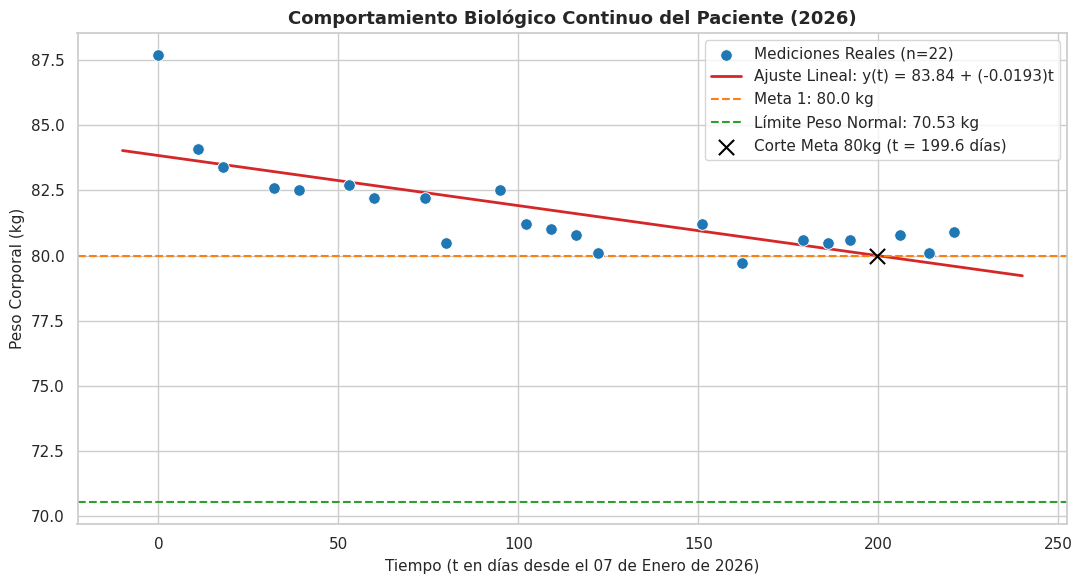

In [15]:
# 5. Visualización Gráfica con Seaborn y Matplotlib
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Scatter plot con mediciones reales
sns.scatterplot(x=t, y=y, color='#1f77b4', s=70, label='Mediciones Reales (n=22)', zorder=5)

# Recta de ajuste lineal
t_linea = np.linspace(-10, 240, 200)
plt.plot( t_linea, beta_0 + beta_1 * t_linea, color="#d62728",  linewidth=2, label=f"Ajuste Lineal: y(t) = {float(beta_0):.2f} + ({float(beta_1):.4f})t",)

# Líneas horizontales de referencia
plt.axhline(y=80.0, color='#ff7f0e', linestyle='--', linewidth=1.5, label='Meta 1: 80.0 kg')
plt.axhline(y=70.53, color='#2ca02c', linestyle='--', linewidth=1.5, label='Límite Peso Normal: 70.53 kg')

# Marcador para la intersección de 80.0 kg
plt.scatter( [float(t_corte_80)], [80.0],color="black", marker="x",s=120, zorder=6,label=f"Corte Meta 80kg (t = {float(t_corte_80):.1f} días)",)

plt.title('Comportamiento Biológico Continuo del Paciente (2026)', fontsize=13, fontweight='bold')
plt.xlabel('Tiempo (t en días desde el 07 de Enero de 2026)', fontsize=11)
plt.ylabel('Peso Corporal (kg)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()